# Atendimento por redes de água e esgoto no Brasil em 2024

**Guilherme Daflon Goulart Costa e Marcella Guimaraes Rodrigues Da Silva**  
**Centro Universitário La Salle do Rio de Janeiro** · Sistemas de Informação, 6º período  
**Linguagens de Programação · 2026.2** · Professor Alexandre Neves Louzada

Projeto Prático G2. Fonte: [Resultados SINISA 2025](https://www.gov.br/cidades/pt-br/acesso-a-informacao/acoes-e-programas/saneamento/sinisa/resultados-sinisa/resultados-sinisa-2025), ano de referência 2024.

1. Como a diferença entre os indicadores totais de água e esgoto varia entre as regiões e UFs?
2. Quanto o atendimento urbano difere do rural em cada serviço?
3. Nos municípios com ambos os indicadores válidos, qual é a dispersão das diferenças e como os dois indicadores se associam?

## 1. Carregamento e tratamento

No ambiente local, execute a partir do projeto ou da pasta `notebooks/`. No Colab, a célula busca os scripts e os quatro XLSX no repositório público. Os percentuais vêm das planilhas oficiais. A ETL valida os arquivos, localiza os cabeçalhos pelos códigos, trata marcadores de ausência e gera os CSVs.

In [1]:
from importlib.util import find_spec
from pathlib import Path
from urllib.request import urlretrieve
import subprocess
import sys

pasta_atual = Path.cwd()
raiz = next((p for p in (pasta_atual, pasta_atual.parent) if (p / "src/etl.py").is_file()), None)

if raiz is None:
    raiz = pasta_atual / "projeto-saneamento-sinisa"
    remoto = "https://raw.githubusercontent.com/daflon-prognum/lasalle/main/projeto-saneamento-sinisa"
    arquivos = [
        "src/__init__.py", "src/etl.py", "src/analise.py",
        "data/raw/agua_municipal.xlsx", "data/raw/agua_uf.xlsx",
        "data/raw/esgoto_municipal.xlsx", "data/raw/esgoto_uf.xlsx",
    ]
    for arquivo in arquivos:
        destino = raiz / arquivo
        if not destino.exists():
            destino.parent.mkdir(parents=True, exist_ok=True)
            parcial = destino.with_suffix(".part")
            urlretrieve(f"{remoto}/{arquivo}", parcial)
            parcial.replace(destino)
    if find_spec("openpyxl") is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "openpyxl==3.1.5"])

sys.path.insert(0, str(raiz))
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src.etl import executar
from src.analise import (
    carregar, diagnostico, grafico_regioes,
    grafico_urbano_rural, pares_validos, resumo_municipal,
)

saida = raiz / "data/processed"
executar(raiz / "data/raw", saida)
municipios, territorios = carregar(saida)
auditoria = json.loads((saida / "auditoria.json").read_text(encoding="utf-8"))

In [2]:
presenca = municipios["presenca"].value_counts().rename_axis("Presença").rename("Municípios")
print(f"União: {len(municipios)} códigos IBGE")
display(presenca.to_frame())

registros = []
for arquivo, detalhes in auditoria.items():
    if arquivo.endswith("_municipal.xlsx"):
        for variavel, contagens in detalhes["indicadores"].items():
            registros.append({
                "arquivo": arquivo,
                "variável": variavel,
                "linhas": detalhes["linhas"],
                "válidos": contagens["validos"],
                "zeros válidos": contagens["zeros"],
                "sem cálculo": sum(contagens["marcadores"].values()),
            })
display(pd.DataFrame(registros))

União: 5149 códigos IBGE


,Municípios
Presença,
Ambos,2744
Somente água,2400
Somente esgoto,5


,arquivo,variável,linhas,válidos,zeros válidos,sem cálculo
0,agua_municipal.xlsx,agua_rural_pct,5144,5089,2076,55
1,agua_municipal.xlsx,agua_total_pct,5144,5118,33,26
2,agua_municipal.xlsx,agua_urbana_pct,5144,5095,42,49
3,esgoto_municipal.xlsx,esgoto_rural_pct,2749,2698,1710,51
4,esgoto_municipal.xlsx,esgoto_total_pct,2749,2728,5,21
5,esgoto_municipal.xlsx,esgoto_urbana_pct,2749,2724,18,25


As planilhas municipais têm 5.144 registros de água e 2.749 de esgoto. Dos 2.744 códigos em ambas, 34 ficaram fora da comparação pareada por ausência em pelo menos um indicador total. Os zeros publicados continuam nos cálculos.

## 2. RQ1 — Diferenças entre regiões e UFs

A diferença em pontos percentuais é calculada por `água total − esgoto total`. Os valores nacionais e regionais são os consolidados do SINISA, calculados com as regras e bases de cada módulo.

,territorio,agua_total_pct,esgoto_total_pct,diferenca_total_pp
0,Brasil,84.14,62.30,21.84
1,Norte,62.81,24.65,38.16
2,Nordeste,73.70,35.90,37.80
3,Sudeste,92.11,81.94,10.17
4,Sul,88.32,57.72,30.60
5,Centro-Oeste,89.71,68.31,21.40


,territorio,agua_total_pct,esgoto_total_pct,diferenca_total_pp
0,Amapá,71.29,9.29,62.00
1,Santa Catarina,89.56,35.89,53.67
2,Alagoas,73.27,22.32,50.95
3,Amazonas,81.28,32.26,49.02
4,Tocantins,84.23,37.02,47.21
5,Rio Grande do Norte,76.38,31.41,44.97
6,Pernambuco,71.56,29.35,42.21
7,Sergipe,93.74,51.63,42.11
8,Rondônia,53.51,13.28,40.23
9,Ceará,72.17,32.60,39.57


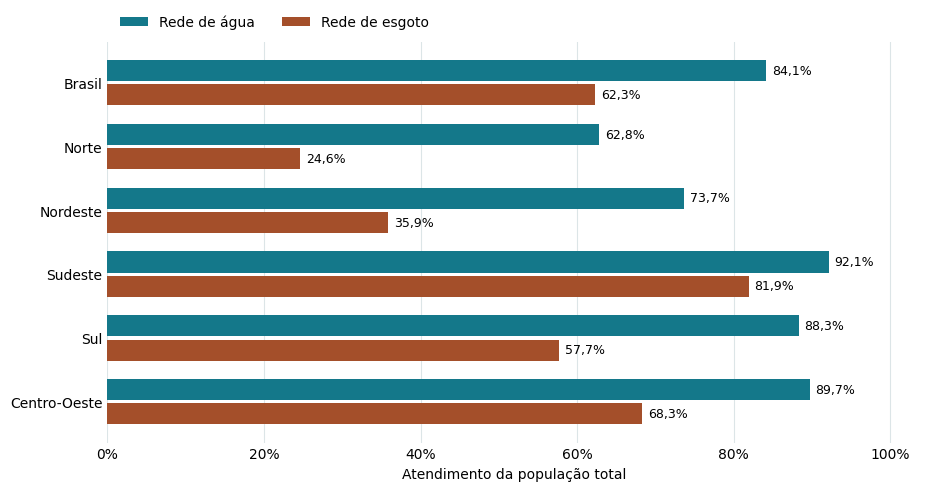

In [3]:
totais = ["agua_total_pct", "esgoto_total_pct", "diferenca_total_pp"]
display(territorios.loc[territorios["nivel"].ne("UF"), ["territorio", *totais]])
ufs = territorios.loc[territorios["nivel"].eq("UF"), ["territorio", *totais]]
display(ufs.sort_values("diferenca_total_pp", ascending=False).reset_index(drop=True))
figura = grafico_regioes(territorios)
display(figura)
plt.close(figura)

A diferença nacional é de **21,84 p.p.** O Norte tem o maior valor entre as macrorregiões (**38,16 p.p.**), seguido pelo Nordeste (**37,80 p.p.**). A menor diferença regional está no Sudeste (**10,17 p.p.**). Entre as UFs, os extremos são Amapá (**62,00 p.p.**) e São Paulo (**4,08 p.p.**).

## 3. RQ2 — Atendimento urbano e rural

Dentro de cada módulo, calculamos a diferença entre os percentuais urbano e rural. Cada taxa usa a população de referência do próprio recorte.

,territorio,agua_urbana_pct,agua_rural_pct,hiato_agua_pp,esgoto_urbana_pct,esgoto_rural_pct,hiato_esgoto_pp
0,Brasil,92.32,22.88,69.44,68.44,4.75,63.69
1,Norte,74.93,13.27,61.66,27.68,1.05,26.63
2,Nordeste,85.34,29.86,55.48,43.45,2.81,40.64
3,Sudeste,96.18,21.42,74.76,85.80,11.23,74.57
4,Sul,97.51,17.22,80.29,63.32,2.74,60.58
5,Centro-Oeste,96.95,9.44,87.51,73.28,2.73,70.55


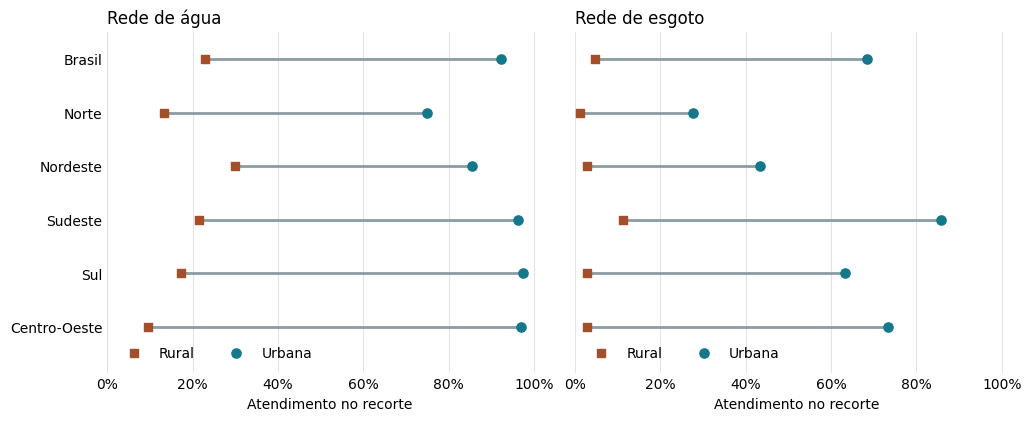

In [4]:
recortes = [
    "territorio", "agua_urbana_pct", "agua_rural_pct", "hiato_agua_pp",
    "esgoto_urbana_pct", "esgoto_rural_pct", "hiato_esgoto_pp",
]
display(territorios.loc[territorios["nivel"].ne("UF"), recortes])
figura = grafico_urbano_rural(territorios)
display(figura)
plt.close(figura)

No Brasil, a diferença urbano–rural é de **69,44 p.p.** em água e **63,69 p.p.** em esgoto. O maior hiato regional em água está no Centro-Oeste (**87,51 p.p.**). Em esgoto, o maior hiato aparece no Sudeste (**74,57 p.p.**). O uso de poços, fossas e outras soluções fora das redes está além deste recorte.

## 4. RQ3 — Dispersão e associação municipal

Para cada município pareado, usamos a diferença com sinal. O intervalo interquartil é Q3 − Q1. Valores abaixo de Q1 − 1,5 × IQR ou acima de Q3 + 1,5 × IQR ficam sinalizados como extremos descritivos. Os coeficientes de Pearson e Spearman medem, respectivamente, associação linear e associação monotônica por postos.

In [5]:
pares = pares_validos(municipios)
display(resumo_municipal(pares).round(4))
display(pd.Series(diagnostico(pares), name="Valor").round(3).to_frame())

campos = ["municipio", "uf", *totais]
display(pares.nlargest(3, "diferenca_total_pp")[campos])
display(pares.nsmallest(3, "diferenca_total_pp")[campos])

,n,mediana,q1,q3
regiao,,,,
Norte,62,34.095,13.9175,47.8675
Nordeste,573,36.250,13.4100,54.9500
Sudeste,1439,3.550,0.0000,13.6150
Sul,444,25.790,8.0700,52.8350
Centro-Oeste,192,20.590,4.8350,43.5650


,Valor
n,2710.000
media_pp,19.439
mediana_pp,10.815
desvio_padrao_pp,26.422
q1_pp,0.690
q3_pp,35.025
pearson,0.493
spearman,0.541
abaixo_limite_iqr,8.000
acima_limite_iqr,40.000


,municipio,uf,agua_total_pct,esgoto_total_pct,diferenca_total_pp
238,Ulianópolis,PA,100.00,0.25,99.75
571,Barra D Alcântara,PI,99.19,0.02,99.17
4428,Imbé,RS,99.99,1.23,98.76


,municipio,uf,agua_total_pct,esgoto_total_pct,diferenca_total_pp
2144,Cuparaque,MG,20.33,86.53,-66.20
1105,Riacho de Santo Antônio,PB,0.00,65.07,-65.07
2050,Caparaó,MG,34.99,100.00,-65.01


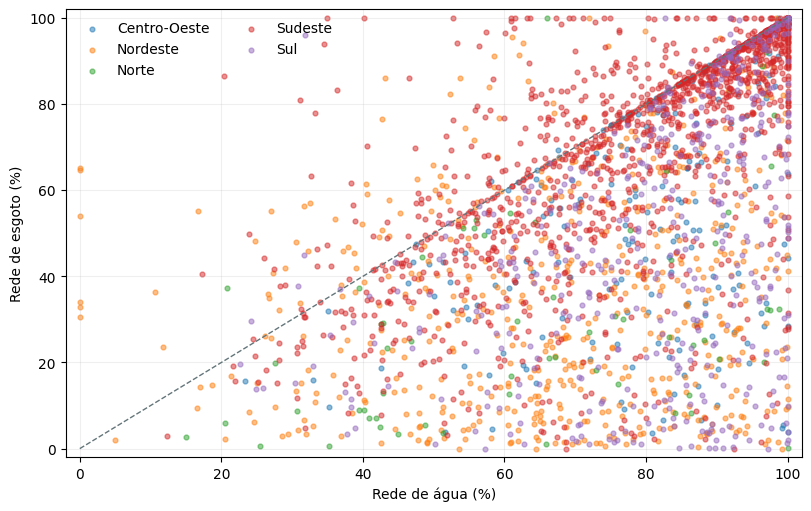

In [6]:
# No HTML do artigo o gráfico é interativo. Aqui, a tabela e a figura estática
# também ficam visíveis no visualizador de notebooks do GitHub.
fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
for regiao, grupo in pares.groupby("regiao"):
    ax.scatter(grupo["agua_total_pct"], grupo["esgoto_total_pct"], label=regiao, s=12, alpha=0.5)
ax.plot([0, 100], [0, 100], "--", color="#64757a", linewidth=1)
ax.set(xlim=(-2, 102), ylim=(-2, 102), xlabel="Rede de água (%)", ylabel="Rede de esgoto (%)")
ax.legend(frameon=False, loc="upper left", ncols=2)
ax.grid(alpha=0.2)
display(fig)
plt.close(fig)

A diferença mediana é **10,82 p.p.** (Q1 = 0,69 e Q3 = 35,025 p.p.). O desvio-padrão é de **26,42 p.p.** e há 48 pontos além dos limites de 1,5 IQR, mantidos na análise. Pearson (**0,493**) e Spearman (**0,541**) indicam associação positiva no conjunto pareado. O Sudeste concentra 1.439 dos 2.710 pares, enquanto o Norte tem 62.

Ulianópolis (PA) ilustra a diferença positiva mais alta (**99,75 p.p.**). Em Cuparaque (MG), o atendimento por rede de esgoto foi maior que por rede de água, com diferença de **−66,20 p.p.**. Em 334 municípios, a diferença ficou abaixo de zero. Esses casos ajudam a evitar que a comparação nacional seja lida como regra para todos os municípios.

## 5. Conclusão

Os indicadores totais de água e esgoto estão mais afastados no Norte e no Nordeste. No recorte nacional, os percentuais rurais são inferiores aos urbanos em ambos os serviços. A análise municipal mostra que os serviços se associam, com diferenças amplas mesmo entre municípios com percentuais de água semelhantes.

Os módulos têm universos de observação distintos. A diferença entre os percentuais mede a distância entre taxas publicadas e não permite identificar a interseção das pessoas atendidas. A análise tem um único ano de referência e não permite atribuir causas. Um próximo recorte pode combinar a base de gestão municipal com soluções alternativas e testar estabilidade em outras edições do SINISA.

[Artigo e gráficos interativos](https://daflon-prognum.github.io/lasalle/projeto-saneamento-sinisa/) · [Código e dicionário](https://github.com/daflon-prognum/lasalle/tree/main/projeto-saneamento-sinisa)